I.) PFC miRNA data: loading, annotations and quality control

We inspect the GSE29356 processed PFC expression file and the local GEO annotation. Before filtering, we check sample identifiers, missing values, repeated features and expression distributions. Sample and miRNA exclusions will be decided after examining the results. The processed PFC expression file and GPL10850 family.soft annotation should be in the data folder.

1.) Import libraries


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import GEOparse


2.) Load PFC miRNA data into a dataframe

In [2]:
pfc_mirna_file = "data/GSE29356_processed_data_pfc.txt"


pfc_mirna = pd.read_csv(
    pfc_mirna_file,
    sep="\t",
    comment="!",
    index_col=0
)
# export simple file
pfc_mirna.to_csv("data/pfc_mirna_expression.csv")

3.) Have a look at the data

In [3]:
print(pfc_mirna.shape)

print(pfc_mirna.head())

(198, 27)
             Hsa_PFC_3days  Hsa_PFC_5days  Hsa_PFC_95days  Hsa_PFC_788days  \
ID_REF                                                                       
hsa-let-7a       12.509508      12.509508       12.964535        12.706113   
hsa-let-7b       12.328442      12.328442       12.328442        12.173784   
hsa-let-7b*       4.371074       3.705721        3.541066         3.290490   
hsa-let-7c       11.474729      11.651839       11.474729        10.782649   
hsa-let-7d        9.452227       9.575366        9.407652         9.575366   

             Hsa_PFC_1631days  Hsa_PFC_9278days  Hsa_PFC_24091days  \
ID_REF                                                               
hsa-let-7a          12.509508         13.416576          12.964535   
hsa-let-7b          12.005529         12.509508          12.005529   
hsa-let-7b*          3.705721          3.172556           3.674399   
hsa-let-7c          10.782649         10.713628          10.612121   
hsa-let-7d           9.

In [4]:
len(pfc_mirna.columns)
pfc_mirna.columns

Index(['Hsa_PFC_3days', 'Hsa_PFC_5days', 'Hsa_PFC_95days', 'Hsa_PFC_788days',
       'Hsa_PFC_1631days', 'Hsa_PFC_9278days', 'Hsa_PFC_24091days',
       'Hsa_PFC_32121days', 'Ptr_PFC_1days', 'Ptr_PFC_2days', 'Ptr_PFC_40days',
       'Ptr_PFC_526days', 'Ptr_PFC_2314days', 'Ptr_PFC_16132days',
       'Ptr_PFC_4362days', 'Ptr_PFC_12785days', 'Ptr_PFC_9days',
       'Ptr_PFC_46days', 'Ptr_PFC_4416days', 'Mml_PFC_2days', 'Mml_PFC_8days',
       'Mml_PFC_17days', 'Mml_PFC_450days', 'Mml_PFC_1488days',
       'Mml_PFC_3390days', 'Mml_PFC_8105days', 'Mml_PFC_10221days'],
      dtype='str')

In [5]:
round(pfc_mirna.describe(),2)

,Hsa_PFC_3days,Hsa_PFC_5days,Hsa_PFC_95days,Hsa_PFC_788days,Hsa_PFC_1631days,Hsa_PFC_9278days,Hsa_PFC_24091days,Hsa_PFC_32121days,Ptr_PFC_1days,Ptr_PFC_2days,...,Ptr_PFC_46days,Ptr_PFC_4416days,Mml_PFC_2days,Mml_PFC_8days,Mml_PFC_17days,Mml_PFC_450days,Mml_PFC_1488days,Mml_PFC_3390days,Mml_PFC_8105days,Mml_PFC_10221days
count,198.00,198.00,198.00,198.00,198.00,198.00,198.00,198.00,198.00,198.00,...,198.00,198.00,198.00,198.00,198.00,198.00,198.00,198.00,198.00,198.00
mean,6.73,6.76,6.72,6.74,6.69,6.80,6.75,6.72,6.72,6.74,...,6.61,6.72,6.75,6.72,6.73,6.73,6.70,6.74,6.73,6.74
std,2.43,2.41,2.41,2.38,2.37,2.43,2.39,2.41,2.33,2.38,...,2.40,2.38,2.36,2.37,2.36,2.33,2.36,2.34,2.36,2.34
min,2.28,1.84,1.84,1.84,1.84,2.28,1.84,1.84,2.68,2.42,...,1.89,2.11,1.84,1.84,1.84,1.84,1.84,1.84,1.84,1.84
25%,4.83,4.96,4.92,4.89,4.85,4.98,4.92,4.89,4.93,4.91,...,4.80,4.90,4.98,4.89,4.94,4.93,4.91,4.96,4.87,4.98
50%,6.42,6.44,6.31,6.29,6.34,6.40,6.38,6.36,6.37,6.38,...,6.25,6.35,6.42,6.37,6.37,6.45,6.37,6.38,6.42,6.40
75%,8.37,8.29,8.32,8.37,8.29,8.43,8.40,8.37,8.32,8.35,...,8.29,8.29,8.29,8.32,8.32,8.32,8.32,8.36,8.36,8.40
max,13.94,13.94,13.94,13.94,13.94,13.94,13.94,13.94,13.45,13.98,...,13.92,13.32,13.42,13.42,13.42,13.42,12.96,12.96,13.42,13.42


4.) The info Table S1 shows more than 27 individuals, but the array shows 27. We have to find out which onese were taken out. We will use GEOparse on the info file "_family.soft"

In [6]:
gse = GEOparse.get_GEO(
    filepath="data/GSE29356_family.soft",
    include_data=True,
    silent=False
) 

30-Oct-2026 01:14:02 INFO GEOparse - Parsing data/GSE29356_family.soft: 
30-Oct-2026 01:14:02 DEBUG GEOparse - DATABASE: GeoMiame
30-Oct-2026 01:14:02 DEBUG GEOparse - SERIES: GSE29356
30-Oct-2026 01:14:02 DEBUG GEOparse - PLATFORM: GPL10850
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725622
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725623
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725624
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725625
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725626
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725627
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725628
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725629
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725630
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725631
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725632
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725633
30-Oct-2026 01:14:02 DEBUG GEOparse - SAMPLE: GSM725634
30-Oct-2026 01:14:02 DEBUG GEO

5.) GEOparse creates a Python object containing the studies information. gse.gsms is a a Python dictionary containing the sample objects. We check how many there are.

In [7]:
print(type(gse))
print(gse.name)
print(len(gse.gsms))

<class 'GEOparse.GEOTypes.GSE'>
GSE29356
64


6.) We check the metadata for one individual

In [8]:
test_ind = gse.gsms["GSM725682"]

print( f"Name : {test_ind.name}")
print( f"Metadata : {test_ind.metadata}")
print( f"Table : {test_ind.table}")
print( f"Columns : {test_ind.columns}")



Name : GSM725682
Metadata : {'title': ['24090 days old human cerebellar cortex batch 1'], 'geo_accession': ['GSM725682'], 'status': ['Public on Dec 09 2011'], 'submission_date': ['May 17 2011'], 'last_update_date': ['Dec 10 2011'], 'type': ['RNA'], 'channel_count': ['1'], 'source_name_ch1': ['Dissected post-mortem human cerebellar cortex'], 'organism_ch1': ['Homo sapiens'], 'taxid_ch1': ['9606'], 'characteristics_ch1': ['age: 24090 days old', 'Sex: M', 'tissue: cerebellar cortex of the brain', 'batch: 1', 'individual no: 7'], 'treatment_protocol_ch1': ['We used prefrontal cortex (PFC) and cerebellar cortex (CBC) samples from postmortem brains of human, chimpanzee, and rhesus macaque individuals of different age. Human samples were obtained from the NICHD Brain and Tissue Bank for Developmental Disorders at the University of Maryland, USA, the Netherlands Brain Bank, Amsterdam, Netherlands, and the Chinese Brain Bank Center, Wuhan, China. Informed consent for use of human tissues for re

7.) We check the metadata 

In [9]:
records = []

for gsm_id, gsm in gse.gsms.items():
    records.append({
        "GSM": gsm_id,
        "Title": gsm.metadata.get("title", [None])[0],
        "Source": gsm.metadata.get("source_name_ch1", [None])[0],
        "Characteristics": gsm.metadata.get("characteristics_ch1", []),
        "Description": gsm.metadata.get("description", [])
    })

sample_info = pd.DataFrame(records)

sample_info['Description']


0     [MicroRNA expression data from post-mortem CBC...
1     [MicroRNA expression data from post-mortem PFC...
2     [MicroRNA expression data from post-mortem PFC...
3     [MicroRNA expression data from post-mortem PFC...
4     [MicroRNA expression data from post-mortem PFC...
                            ...                        
59    [MicroRNA expression data from post-mortem CBC...
60    [MicroRNA expression data from post-mortem CBC...
61    [MicroRNA expression data from post-mortem PFC...
62    [MicroRNA expression data from post-mortem CBC...
63    [MicroRNA expression data from post-mortem PFC...
Name: Description, Length: 64, dtype: object

In [10]:
print(sample_info[["GSM", "Title"]].to_string(index=False))

sample_info.to_csv("data/pfc_mirna_sample_info.csv", index=False)

      GSM                                               Title
GSM725622   525 days old chimpanzee cerebellar cortex batch 1
GSM725623   525 days old chimpanzee prefrontal cortex batch 2
GSM725624   525 days old chimpanzee prefrontal cortex batch 1
GSM725625     0 days old chimpanzee prefrontal cortex batch 1
GSM725626     0 days old chimpanzee prefrontal cortex batch 2
GSM725627     0 days old chimpanzee cerebellar cortex batch 1
GSM725628        787 days old human cerebellar cortex batch 1
GSM725629        787 days old human prefrontal cortex batch 1
GSM725630     1 days old chimpanzee cerebellar cortex batch 1
GSM725631     1 days old chimpanzee prefrontal cortex batch 2
GSM725632     1 days old chimpanzee prefrontal cortex batch 1
GSM725633    45 days old chimpanzee prefrontal cortex batch 2
GSM725634    39 days old chimpanzee cerebellar cortex batch 1
GSM725635    39 days old chimpanzee prefrontal cortex batch 2
GSM725636    39 days old chimpanzee prefrontal cortex batch 1
GSM72563

7.i) Add species and age information to sample_info

In [11]:
sample_info["Species"] = (
    sample_info["Title"]
    .str.extract(r"\b(human|chimpanzee|macaque)", expand=False)
)

sample_info["Age_days"] = pd.to_numeric(
    sample_info["Title"]
    .str.extract(r"(\d+)\s+days?\s+old", expand=False),
    errors="coerce"
)

sample_info["Region"] = (
    sample_info["Description"]
    .str[0]
    .str.extract(r"\b(PFC|CBC)", expand=False)
)

#convert to lower case and save as number
sample_info["Species"] = sample_info["Species"].str.lower()
sample_info["Age_days"] = pd.to_numeric(sample_info["Age_days"])
sample_info["Age_processed"] = sample_info["Age_days"] + 1

print(sample_info.head())

sample_info.to_csv("data/pfc_mirna_sample_info.csv", index=False)

         GSM                                              Title  \
0  GSM725622  525 days old chimpanzee cerebellar cortex batch 1   
1  GSM725623  525 days old chimpanzee prefrontal cortex batch 2   
2  GSM725624  525 days old chimpanzee prefrontal cortex batch 1   
3  GSM725625    0 days old chimpanzee prefrontal cortex batch 1   
4  GSM725626    0 days old chimpanzee prefrontal cortex batch 2   

                                              Source  \
0  Dissected post-mortem chimpanzee cerebellar co...   
1  Dissected post-mortem chimpanzee prefrontal co...   
2  Dissected post-mortem chimpanzee prefrontal co...   
3  Dissected post-mortem chimpanzee prefrontal co...   
4  Dissected post-mortem chimpanzee prefrontal co...   

                                     Characteristics  \
0  [age: 525 days old, Sex: F, tissue: cerebellar...   
1  [age: 525 days old, Sex: F, tissue: prefrontal...   
2  [age: 525 days old, Sex: F, tissue: prefrontal...   
3  [age: 0 days old, Sex: M, tissue:

8.) We try to math the column info from the processed data to the GSMids 

In [12]:
# creating a new dataframe with the info

species_codes = {
    "Hsa": "human",
    "Ptr": "chimpanzee",
    "Mml": "macaque"
}

data_info = pd.DataFrame({
    "Sample": pfc_mirna.columns
})

data_info[["Code", "Region", "Age_days"]] = (
    data_info["Sample"]
    .str.extract(r"^(Hsa|Ptr|Mml)_(PFC)_(\d+)days$")
)


data_info["Species"] = data_info["Code"].map(species_codes)
data_info["Age_days"] = pd.to_numeric(data_info["Age_days"])

display(data_info.head())



,Sample,Code,Region,Age_days,Species
0,Hsa_PFC_3days,Hsa,PFC,3,human
1,Hsa_PFC_5days,Hsa,PFC,5,human
2,Hsa_PFC_95days,Hsa,PFC,95,human
3,Hsa_PFC_788days,Hsa,PFC,788,human
4,Hsa_PFC_1631days,Hsa,PFC,1631,human


8.) Do the matching and check if matches are unique

In [13]:
#The argument how="left" means that we keep all 27 processed samples

matches = data_info.merge(
    sample_info[["GSM", "Species", "Region", "Age_processed"]],
    left_on=["Species", "Region", "Age_days"],
    right_on=["Species", "Region", "Age_processed"],
    how="left"
)

display(matches)


,Sample,Code,Region,Age_days,Species,GSM,Age_processed
0,Hsa_PFC_3days,Hsa,PFC,3,human,GSM725664,3
1,Hsa_PFC_5days,Hsa,PFC,5,human,GSM725669,5
2,Hsa_PFC_95days,Hsa,PFC,95,human,GSM725662,95
3,Hsa_PFC_788days,Hsa,PFC,788,human,GSM725629,788
4,Hsa_PFC_1631days,Hsa,PFC,1631,human,GSM725641,1631
5,Hsa_PFC_9278days,Hsa,PFC,9278,human,GSM725648,9278
6,Hsa_PFC_24091days,Hsa,PFC,24091,human,GSM725683,24091
7,Hsa_PFC_32121days,Hsa,PFC,32121,human,GSM725680,32121
8,Ptr_PFC_1days,Ptr,PFC,1,chimpanzee,GSM725625,1
9,Ptr_PFC_1days,Ptr,PFC,1,chimpanzee,GSM725626,1


In [14]:
# Count which matches are double 

match_counts = matches.groupby("Sample")["GSM"].count()

print(match_counts.value_counts().sort_index())


GSM
1    22
2     5
Name: count, dtype: int64


In [15]:
mapping = (
    matches.groupby("Sample", sort=False)
    .agg(
        GSM=("GSM", lambda x: list(x.dropna())),
        N_matches=("GSM", "count")
    )
    .reset_index()
)

display(mapping)

,Sample,GSM,N_matches
0,Hsa_PFC_3days,[GSM725664],1
1,Hsa_PFC_5days,[GSM725669],1
2,Hsa_PFC_95days,[GSM725662],1
3,Hsa_PFC_788days,[GSM725629],1
4,Hsa_PFC_1631days,[GSM725641],1
5,Hsa_PFC_9278days,[GSM725648],1
6,Hsa_PFC_24091days,[GSM725683],1
7,Hsa_PFC_32121days,[GSM725680],1
8,Ptr_PFC_1days,"[GSM725625, GSM725626]",2
9,Ptr_PFC_2days,"[GSM725631, GSM725632]",2


In [16]:
ambiguous = mapping[mapping["N_matches"] == 2]

display(ambiguous)

,Sample,GSM,N_matches
8,Ptr_PFC_1days,"[GSM725625, GSM725626]",2
9,Ptr_PFC_2days,"[GSM725631, GSM725632]",2
10,Ptr_PFC_40days,"[GSM725635, GSM725636]",2
11,Ptr_PFC_526days,"[GSM725623, GSM725624]",2
13,Ptr_PFC_16132days,"[GSM725677, GSM725678]",2


In [17]:

sample_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   GSM              64 non-null     str   
 1   Title            64 non-null     str   
 2   Source           64 non-null     str   
 3   Characteristics  64 non-null     object
 4   Description      64 non-null     object
 5   Species          64 non-null     str   
 6   Age_days         64 non-null     int64 
 7   Region           64 non-null     object
 8   Age_processed    64 non-null     int64 
dtypes: int64(2), object(3), str(4)
memory usage: 4.6+ KB


9.) We make a new metadata table and look at the age distribution

In [18]:
# Convert GSM lists to strings
gsm_info = mapping.copy()

gsm_info["GSM"] = gsm_info["GSM"].apply(
    lambda x: ", ".join(x)
)


# Create the final metadata table
sample_info = data_info.merge(
    gsm_info[["Sample", "GSM", "N_matches"]],
    on="Sample",
    how="left",
    validate="one_to_one"
)


# Add original age immediately after Age_days
pos = sample_info.columns.get_loc("Age_days") + 1

sample_info.insert(
    pos, "Original_age_days", sample_info["Age_days"] - 1
)

# Add log2-transformed age immediately after original age
sample_info.insert(
    pos + 1, "Log2_Age", np.log2(sample_info["Age_days"])
)

#save data
sample_info.to_csv(
    "data/pfc_mirna_sample_info.csv",
    index=False
)

#give it a new name
sample_info_clean = sample_info.copy()

In [19]:
sample_info_clean

,Sample,Code,Region,Age_days,Original_age_days,Log2_Age,Species,GSM,N_matches
0,Hsa_PFC_3days,Hsa,PFC,3,2,1.584963,human,GSM725664,1
1,Hsa_PFC_5days,Hsa,PFC,5,4,2.321928,human,GSM725669,1
2,Hsa_PFC_95days,Hsa,PFC,95,94,6.569856,human,GSM725662,1
3,Hsa_PFC_788days,Hsa,PFC,788,787,9.622052,human,GSM725629,1
4,Hsa_PFC_1631days,Hsa,PFC,1631,1630,10.671541,human,GSM725641,1
5,Hsa_PFC_9278days,Hsa,PFC,9278,9277,13.179598,human,GSM725648,1
6,Hsa_PFC_24091days,Hsa,PFC,24091,24090,14.556207,human,GSM725683,1
7,Hsa_PFC_32121days,Hsa,PFC,32121,32120,14.971229,human,GSM725680,1
8,Ptr_PFC_1days,Ptr,PFC,1,0,0.000000,chimpanzee,"GSM725625, GSM725626",2
9,Ptr_PFC_2days,Ptr,PFC,2,1,1.000000,chimpanzee,"GSM725631, GSM725632",2


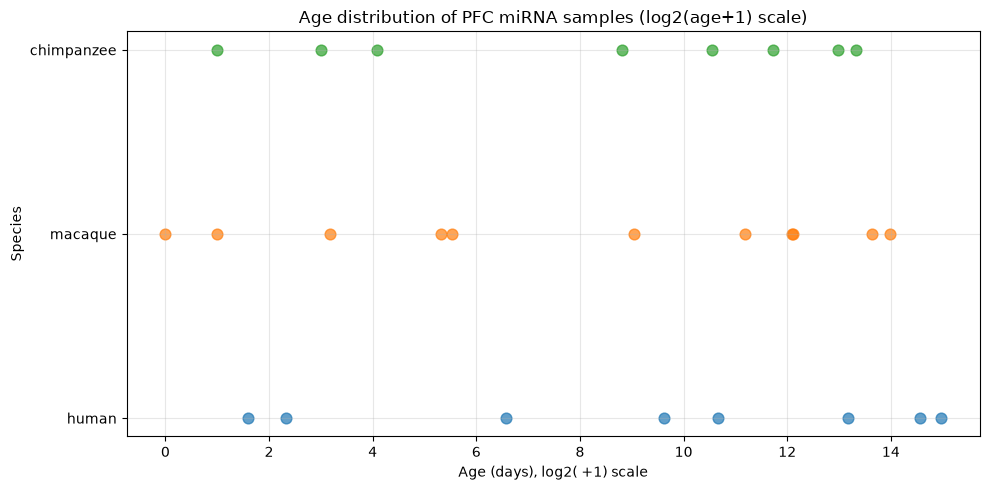

In [20]:
species_order = ["human", "macaque", "chimpanzee"]

plt.figure(figsize=(10, 5))

for species in sample_info_clean["Species"].unique():
    
    subset = sample_info_clean[
        sample_info_clean["Species"] == species
    ]
    
    plt.scatter(
        subset["Log2_Age"],
        [species] * len(subset),
        label=species,
        s=60,
        alpha=0.7
    )

plt.yticks(range(3), species_order)
plt.xlabel("Age (days), log2( +1) scale")
plt.ylabel("Species")
plt.title("Age distribution of PFC miRNA samples (log2(age+1) scale)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

10.) Checking for outliers. We extract the species data and correlate all individuals

In [21]:
species_ids = {}
corr = {}
median_corr = {}

for i in sample_info_clean["Species"].unique():

    info = sample_info_clean[
        sample_info_clean["Species"] == i
    ].copy()

    species_ids[i] = info["Sample"].tolist()

    spec_mirna = pfc_mirna[species_ids[i]]

    corr[i] = spec_mirna.corr()

    median_corr[i] = corr[i].mask(
        np.eye(len(corr[i]), dtype=bool)
    ).median()

    print(f"\nSpecies: {i}")
    display(median_corr[i].sort_values().head(10))



Species: human


Hsa_PFC_3days        0.837363
Hsa_PFC_5days        0.916094
Hsa_PFC_95days       0.946657
Hsa_PFC_32121days    0.955401
Hsa_PFC_1631days     0.963479
Hsa_PFC_24091days    0.964523
Hsa_PFC_788days      0.966258
Hsa_PFC_9278days     0.970577
dtype: float64


Species: chimpanzee


Ptr_PFC_4416days     0.896235
Ptr_PFC_2days        0.904495
Ptr_PFC_9days        0.919233
Ptr_PFC_46days       0.924183
Ptr_PFC_12785days    0.925571
Ptr_PFC_16132days    0.926868
Ptr_PFC_1days        0.932241
Ptr_PFC_526days      0.932694
Ptr_PFC_2314days     0.945101
Ptr_PFC_4362days     0.945990
dtype: float64


Species: macaque


Mml_PFC_2days        0.926681
Mml_PFC_17days       0.938813
Mml_PFC_8days        0.951837
Mml_PFC_450days      0.975966
Mml_PFC_10221days    0.975966
Mml_PFC_1488days     0.979121
Mml_PFC_8105days     0.982705
Mml_PFC_3390days     0.984489
dtype: float64

11.) The analysis reveals 1 human outlier. It is not clear if this is a measurement error or a feature of human development. We look at the correlation with the next individual (see below). It is very high, so we keep it. 

In [22]:
human_samples = sample_info.loc[
    sample_info["Species"] == "human", "Sample"
]

human_corr = pfc_mirna[human_samples].corr()

print(
    human_corr.loc[
        "Hsa_PFC_3days",
        "Hsa_PFC_5days"
    ]
)

0.9495818575588574


12.) We calculate the standard deviation of each miRNA across the 27 measurements and summarize the data

In [23]:
mirna_sd = pfc_mirna.std(axis=1)

print(mirna_sd.describe())

count    198.000000
mean       0.579588
std        0.319981
min        0.200372
25%        0.374458
50%        0.483201
75%        0.710148
max        2.546546
dtype: float64


13.) We look at the miRNAs with the highest variation

In [24]:
mirna_sd = pfc_mirna.std(axis=1)

display(
    mirna_sd.sort_values(ascending=False).head(15)
)


ID_REF
hsa-mir-219-5p      2.546546
hsa-mir-219-2-3p    1.954769
hsa-mir-29b         1.931204
hsa-mir-1225-5p     1.566096
hsa-mir-1915        1.396849
hsa-mir-34a         1.386540
hsa-mir-338-3p      1.267018
hsa-mir-1202        1.244606
hsa-mir-144         1.212983
hsa-mir-130b        1.093876
hsa-mir-451         1.092613
hsa-mir-29c*        1.068144
hsa-mir-299-5p      1.057952
hsa-mir-744*        1.050533
hsa-mir-494         1.043894
dtype: float64

14.) Exploratory data analyis / Correlation between species, age and  age and species

In [25]:
#Transpose matrix
Y = pfc_mirna.T

print(Y.shape)


(27, 198)


In [26]:
#align metadata
info = sample_info.set_index("Sample").loc[Y.index]

In [27]:
# get dummy veriables
age = info[["Log2_Age"]]

species = pd.get_dummies(
    info["Species"],
    drop_first=True,
    dtype=float
)

In [28]:
# create design matrices
X_species = species

X_age = age

X_both = pd.concat([species, age], axis=1)

In [29]:
# use linear regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [30]:
# fit species model
model_species = LinearRegression()
model_species.fit(X_species, Y)

Y_pred_species = model_species.predict(X_species)

#Calculate R^2 value for every gene
r2_species = r2_score(
    Y,
    Y_pred_species,
    multioutput="raw_values"
)

In [31]:
#fit age model

model_age = LinearRegression()
model_age.fit(X_age, Y)

r2_age = r2_score(
    Y,
    model_age.predict(X_age),
    multioutput="raw_values"
)

In [32]:
#fit both age and species

model_both = LinearRegression()
model_both.fit(X_both, Y)

r2_both = r2_score(
    Y,
    model_both.predict(X_both),
    multioutput="raw_values"
)


In [33]:
# create regression results table

regression_results = pd.DataFrame({
    "miRNA": Y.columns,
    "R2_species": r2_species,
    "R2_age": r2_age,
    "R2_both": r2_both
}).set_index("miRNA")

In [34]:
# additional contribution of age and species

regression_results["Age_given_species"] = (
    regression_results["R2_both"]
    - regression_results["R2_species"]
)

regression_results["Species_given_age"] = (
    regression_results["R2_both"]
    - regression_results["R2_age"]
)

In [35]:
# summmarize results

display(regression_results.describe())

,R2_species,R2_age,R2_both,Age_given_species,Species_given_age
count,198.000000,198.000000,198.000000,198.000000,198.000000
mean,0.247713,0.238594,0.496616,0.248904,0.258023
std,0.215570,0.248213,0.234455,0.254740,0.215267
min,0.000333,0.000017,0.028415,0.000025,0.003776
25%,0.070894,0.025915,0.315543,0.028923,0.076800
50%,0.167348,0.143178,0.517433,0.165240,0.184283
75%,0.410864,0.405688,0.678612,0.428464,0.421690
max,0.836423,0.909405,0.951424,0.938495,0.840737


15.) Check which miRNAs have the highest age correlation

In [36]:
display(
    regression_results.sort_values(
        "Age_given_species",
        ascending=False
    ).head(15)
)

,R2_species,R2_age,R2_both,Age_given_species,Species_given_age
miRNA,,,,,
hsa-mir-29c*,0.012929,0.909405,0.951424,0.938495,0.042019
hsa-mir-29b,0.028236,0.869018,0.925484,0.897248,0.056466
hsa-mir-29c,0.009899,0.846698,0.886063,0.876164,0.039365
hsa-mir-34a,0.005250,0.856815,0.862771,0.857522,0.005957
hsa-mir-130a,0.052373,0.796773,0.898032,0.845659,0.101259
hsa-mir-23b,0.012257,0.837260,0.845056,0.832799,0.007796
hsa-mir-181c*,0.057503,0.772174,0.883844,0.826341,0.111670
hsa-mir-490-5p,0.000333,0.806115,0.820249,0.819916,0.014133
hsa-mir-9,0.021543,0.787139,0.829585,0.808042,0.042446
